# Title

In [61]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn
from sklearn import preprocessing

In [63]:
# viewing data
dataset = pd.read_csv("./datasets/heart+disease/processed.cleveland.data")
dataset.head()

,63.0,1.0,1.0.1,145.0,233.0,1.0.2,2.0,150.0,0.0,2.3,3.0,0.0.1,6.0,0
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


In [65]:
# adding headings to data
dataset.columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal','num']
dataset.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


In [67]:
# Converts the following columns from object to float64
#dataset['ca'] = pd.to_numeric(dataset.ca, errors = 'coerce')
#dataset['thal'] = pd.to_numeric(dataset.thal, errors = 'coerce')

In [69]:
# data preprocessing
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    float64
 1   sex       302 non-null    float64
 2   cp        302 non-null    float64
 3   trestbps  302 non-null    float64
 4   chol      302 non-null    float64
 5   fbs       302 non-null    float64
 6   restecg   302 non-null    float64
 7   thalach   302 non-null    float64
 8   exang     302 non-null    float64
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    float64
 11  ca        302 non-null    object 
 12  thal      302 non-null    object 
 13  num       302 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.2+ KB


In [77]:
# Apply One-Hot Encoding to the categorical features in the dataset
from sklearn.preprocessing import OneHotEncoder

categorical_cols = dataset.select_dtypes(include = ['object']).columns.tolist()
one_hot_encoder = OneHotEncoder(sparse_output = False)
encoded_cols = one_hot_encoder.fit_transform(dataset[categorical_cols])
df_encoded_cols = pd.DataFrame(encoded_cols, columns = one_hot_encoder.get_feature_names_out
                               (categorical_cols))
df_encoded = pd.concat([dataset, df_encoded_cols], axis = 1)
df_encoded = df_encoded.drop(categorical_cols, axis = 1)
df_encoded.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,num,ca_0.0,ca_1.0,ca_2.0,ca_3.0,ca_?,thal_3.0,thal_6.0,thal_7.0,thal_?
297,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,...,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
298,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,...,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
299,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,...,3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
300,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,...,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
301,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [303]:
dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,298.000000,300.000000,302.000000
mean,54.410596,0.678808,3.165563,131.645695,246.738411,0.145695,0.986755,149.605960,0.327815,1.035430,1.596026,0.674497,4.730000,0.940397
std,9.040163,0.467709,0.953612,17.612202,51.856829,0.353386,0.994916,22.912959,0.470196,1.160723,0.611939,0.938202,1.941563,1.229384
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,55.500000,1.000000,3.000000,130.000000,241.500000,0.000000,0.500000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [79]:
df_encoded.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,num,ca_0.0,ca_1.0,ca_2.0,ca_3.0,ca_?,thal_3.0,thal_6.0,thal_7.0,thal_?
count,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,...,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.410596,0.678808,3.165563,131.645695,246.738411,0.145695,0.986755,149.605960,0.327815,1.035430,...,0.940397,0.579470,0.215232,0.125828,0.066225,0.013245,0.549669,0.056291,0.387417,0.006623
std,9.040163,0.467709,0.953612,17.612202,51.856829,0.353386,0.994916,22.912959,0.470196,1.160723,...,1.229384,0.494463,0.411665,0.332206,0.249088,0.114512,0.498353,0.230866,0.487969,0.081244
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,55.500000,1.000000,3.000000,130.000000,241.500000,0.000000,0.500000,153.000000,0.000000,0.800000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,...,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,...,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [83]:
df_encoded.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
num         0
ca_0.0      0
ca_1.0      0
ca_2.0      0
ca_3.0      0
ca_?        0
thal_3.0    0
thal_6.0    0
thal_7.0    0
thal_?      0
dtype: int64

In [304]:
# Data visualisation

<Axes: xlabel='num', ylabel='count'>

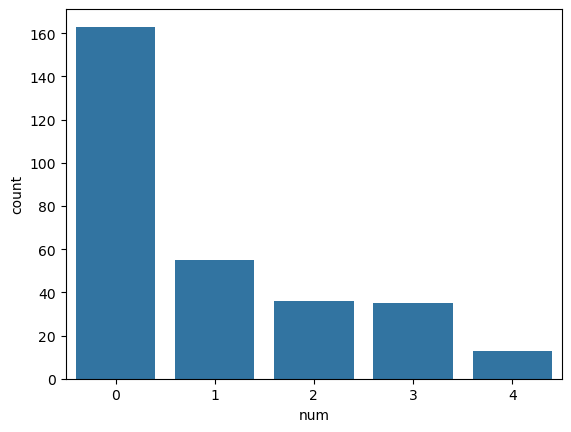

In [85]:
import seaborn as sns

# View counts of predicted values
sns.countplot(x="num", data=dataset)

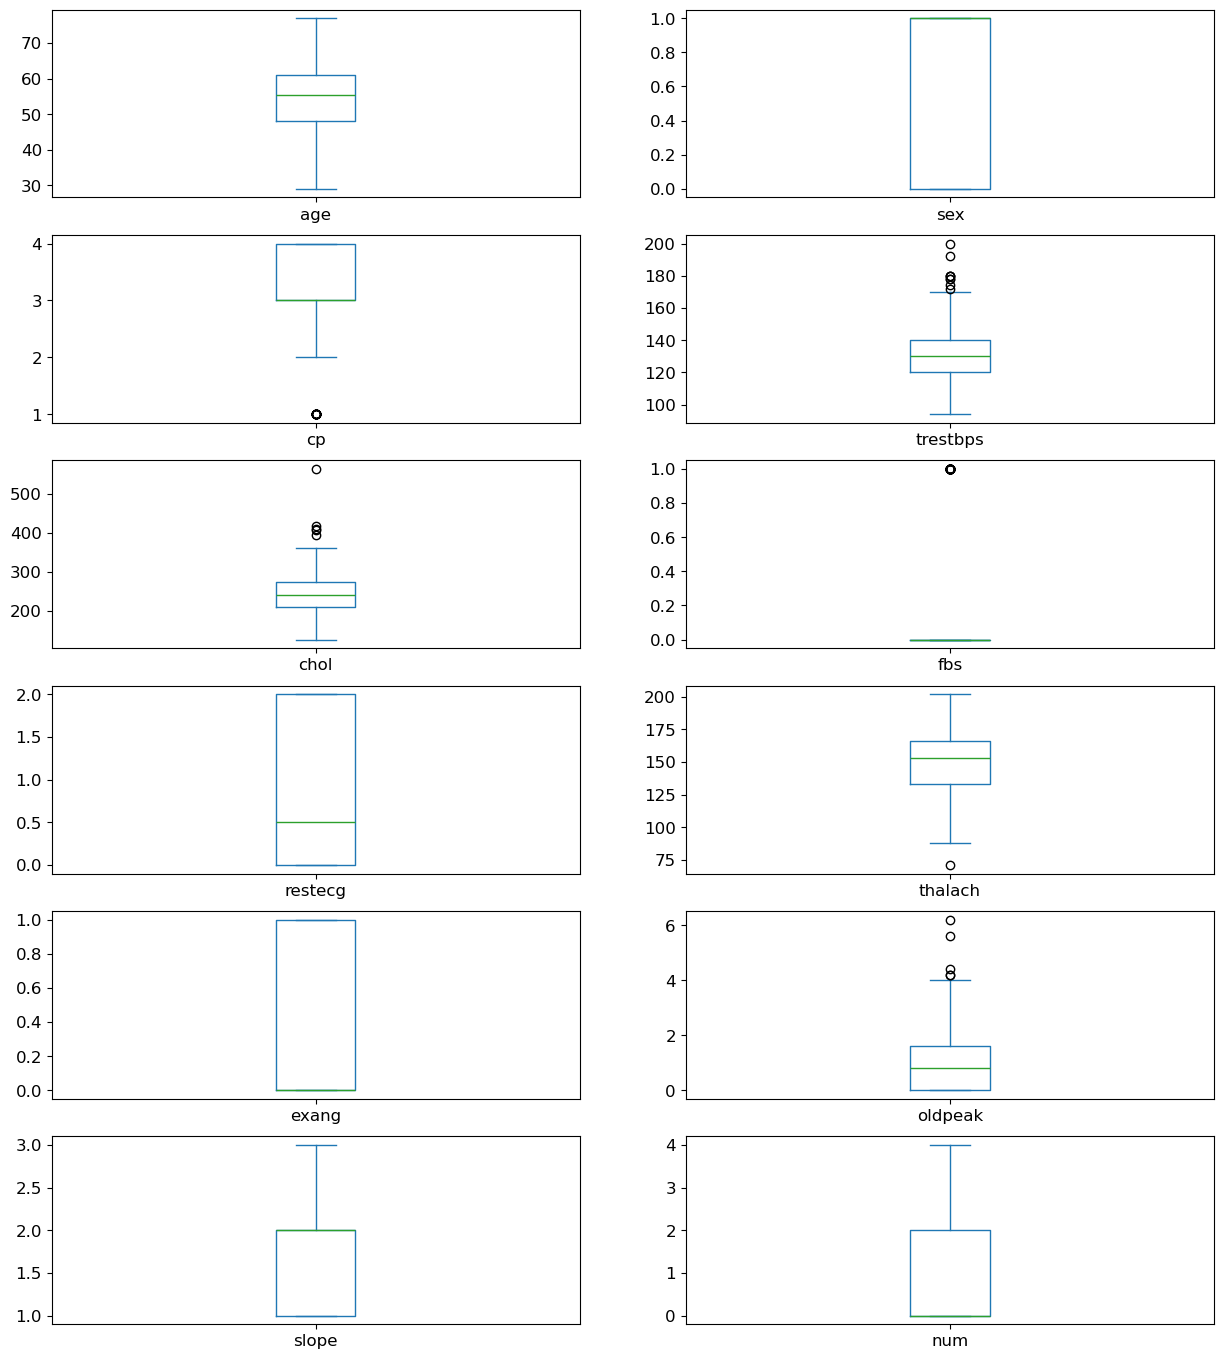

In [87]:
data_mean = dataset.iloc[:, :]
data_mean.plot(kind='box', subplots=True, layout=(7,2), sharex=False,
sharey=False, fontsize=12, figsize=(15,20));

In [307]:
# Data Imputation

In [308]:
# Before removing null values
dataset.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [309]:
# Imputing ca and thal using mode (categorical features)
    # ca is number of major vessels (0-3)
    # thal is condition of heart: (3 = normal, 6 = fixed defect, 7 = reversable defect)

dataset["ca"] = dataset["ca"].fillna(dataset["ca"].mode()[0])
dataset["thal"] = dataset["thal"].fillna(dataset["thal"].mode()[0])
dataset.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

<Axes: >

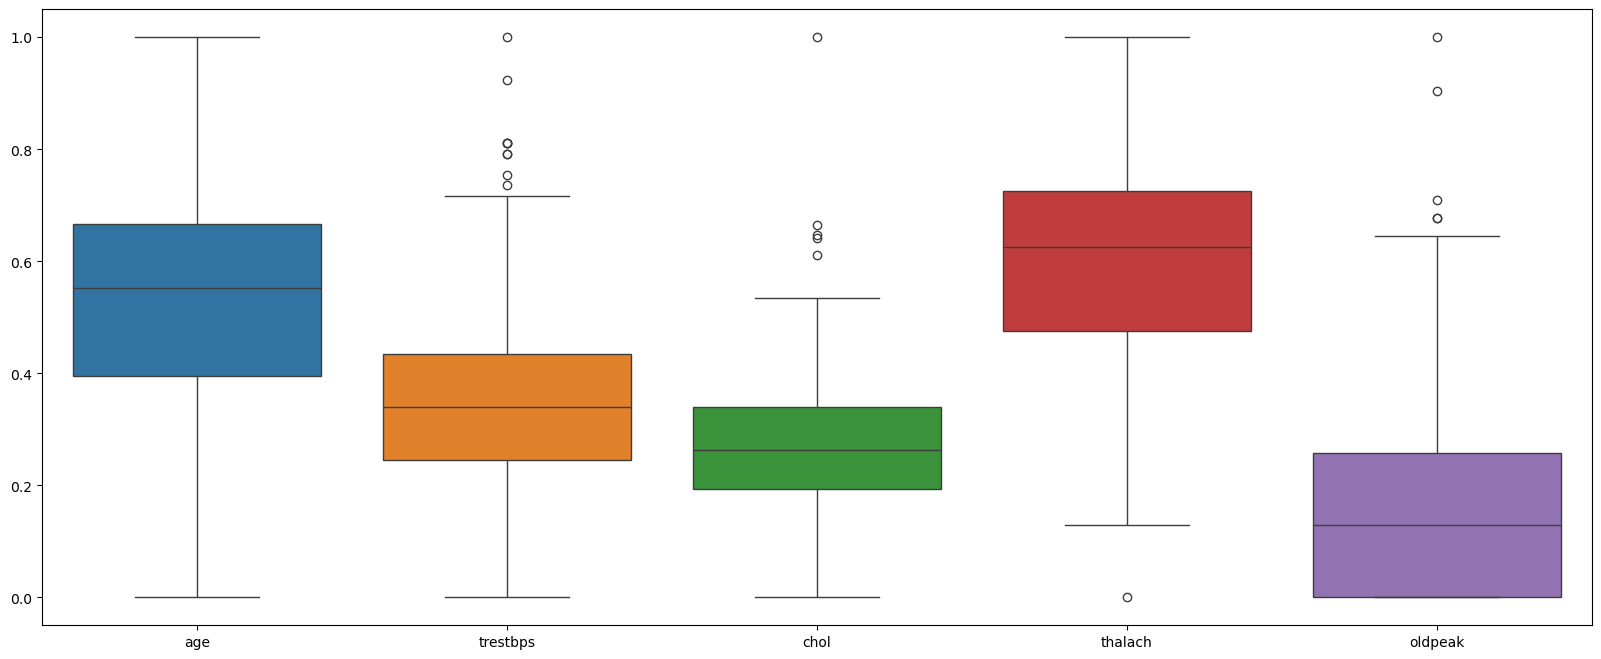

In [310]:
# Feature Normalisation
    # Normalising numerical features to make processing faster etc
        # age, trestbps, chol, thalach, oldpeak
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]] = scaler.fit_transform(dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]])

# Display normalised features
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]],ax=ax)

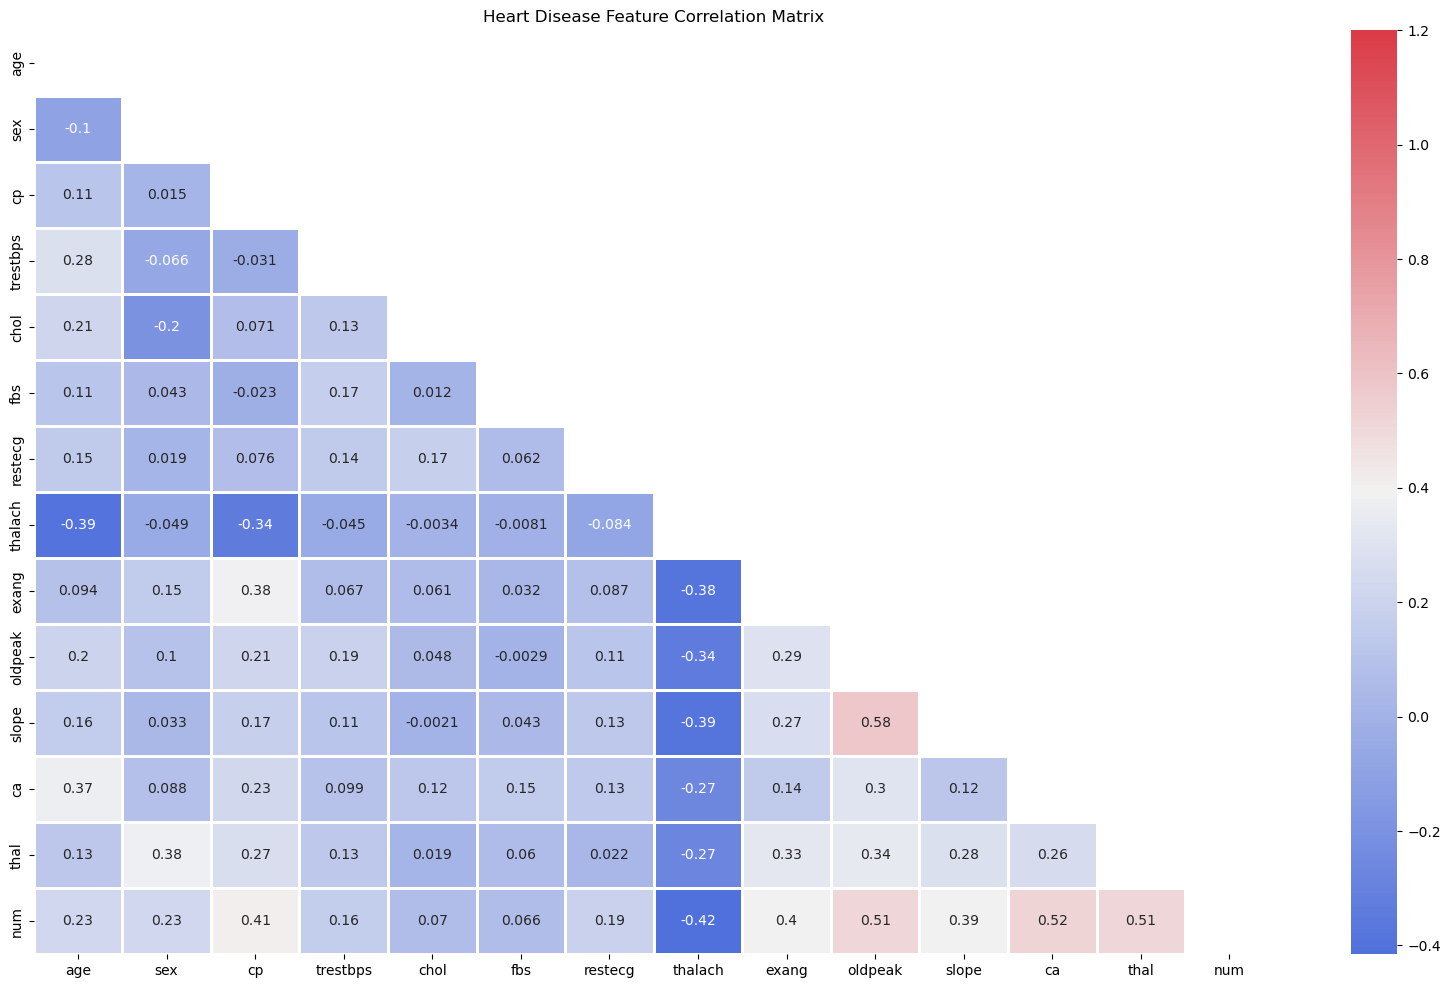

In [311]:
# Confusion Matrix
    # Checking correlation between features

corrMatt = dataset.corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.zeros_like(corrMatt)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(20, 12))
plt.title('Heart Disease Feature Correlation Matrix')

# Generate a custom diverging colormap
cmap = sns.diverging_palette(260, 10, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
ax=ax, annot=True, fmt='.2g', linewidths=1);

In [312]:
# do we remove thalach as a result? questions to pose in the essay if enough words

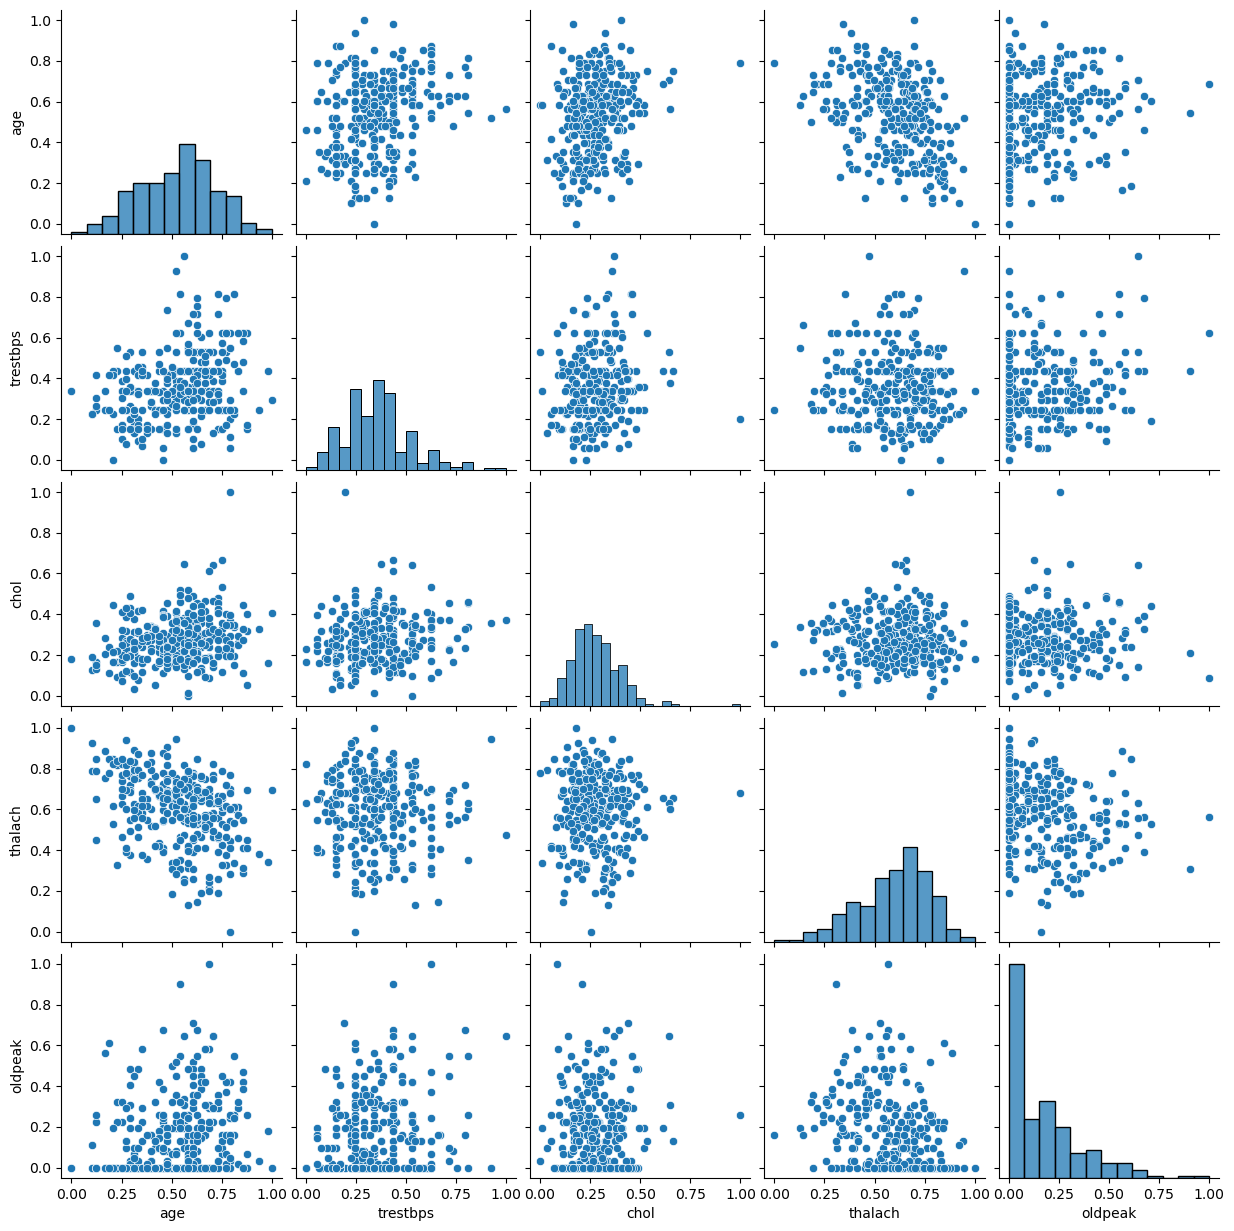

In [313]:
# Correlation-variance diagrams
sns.pairplot(dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]]);

In [314]:
# Results show no clear correlation between numerical features, concerning?

In [351]:
# train-test-validation split
from sklearn.model_selection import train_test_split

Xs = dataset.drop('num', axis=1) # remove num as it is the predicted class, leaving features
y = dataset['num'] # output is the predicted class, num

# Divide data into training (70%) and testing sets (30%)
Xs_train, Xs_test, y_train, y_test = train_test_split(Xs, y, test_size=0.3,random_state=1, stratify=y)

In [353]:
# logistic regression

In [355]:
# support vector machine

In [363]:
# decision trees

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

tree_classifier = DecisionTreeClassifier(max_depth = 2)
tree_classifier.fit(Xs_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [365]:
tree_classifier.predict_proba(Xs_test)

array([[0.92957746, 0.04225352, 0.02816901, 0.        , 0.        ],
       [0.54761905, 0.23809524, 0.0952381 , 0.07142857, 0.04761905],
       [0.92957746, 0.04225352, 0.02816901, 0.        , 0.        ],
       [0.54761905, 0.23809524, 0.0952381 , 0.07142857, 0.04761905],
       [0.54545455, 0.18181818, 0.12121212, 0.09090909, 0.06060606],
       [0.92957746, 0.04225352, 0.02816901, 0.        , 0.        ],
       [0.10769231, 0.29230769, 0.23076923, 0.29230769, 0.07692308],
       [0.10769231, 0.29230769, 0.23076923, 0.29230769, 0.07692308],
       [0.92957746, 0.04225352, 0.02816901, 0.        , 0.        ],
       [0.10769231, 0.29230769, 0.23076923, 0.29230769, 0.07692308],
       [0.10769231, 0.29230769, 0.23076923, 0.29230769, 0.07692308],
       [0.54761905, 0.23809524, 0.0952381 , 0.07142857, 0.04761905],
       [0.92957746, 0.04225352, 0.02816901, 0.        , 0.        ],
       [0.54761905, 0.23809524, 0.0952381 , 0.07142857, 0.04761905],
       [0.10769231, 0.29230769, 0.

In [367]:
classifier_score = tree_classifier.score(Xs_test, y_test)
print("The classifier score of the Decision Tree is: {:03.2f}".format(classifier_score))

The classifier score of the Decision Tree is: 0.56


In [319]:
# neural network

In [320]:
# k-fold cross-validation